In [1]:
#MÉTODO DEL CÓDO-ELBOW

In [2]:
pip install pymysql

Note: you may need to restart the kernel to use updated packages.


In [3]:
!pip install kneed

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sqlalchemy import create_engine
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from kneed import KneeLocator

# CONEXIÓN A MYSQL
usuario = "root"
password = "root"
host = "localhost"
puerto = "3306"
base = "renacertfg"

engine = create_engine(f"mysql+pymysql://{usuario}:{password}@{host}:{puerto}/{base}")

print("Conexión creada correctamente")

Conexión creada correctamente


In [5]:
query = """
WITH base AS (
    SELECT
        fv.cliente_id,
        fv.localidad_id,
        fv.canal_id,
        fv.fecha,
        fv.documento_id,
        fv.serie,
        fv.numero,
        fv.producto_code,
        COALESCE(fv.neto_con_imp, 0) AS neto_con_imp,

        dp.categoria_id,
        cat.name AS categoria,
        dp.marca_id,
        mar.name AS marca

    FROM vw_fact_ventas_tipada fv
    LEFT JOIN dim_productos dp
        ON fv.producto_code = dp.code
    LEFT JOIN dim_categorias cat
        ON dp.categoria_id = cat.id
    LEFT JOIN dim_marcas mar
        ON dp.marca_id = mar.id

    WHERE fv.fecha BETWEEN '2022-01-01' AND '2024-12-31'
      AND fv.cliente_id IS NOT NULL
      AND COALESCE(fv.neto_con_imp, 0) > 0
),

rfm AS (
    SELECT
        cliente_id,
        MAX(localidad_id) AS localidad_id,
        MAX(canal_id) AS canal_id,
        DATEDIFF('2024-12-31', MAX(fecha)) AS recencia,
        COUNT(DISTINCT CONCAT(
            COALESCE(documento_id, ''), '-',
            COALESCE(serie, ''), '-',
            COALESCE(numero, '')
        )) AS frecuencia_compra,
        SUM(neto_con_imp) AS monto_total,
        COUNT(DISTINCT producto_code) AS variedad_productos,
        COUNT(DISTINCT categoria_id) AS cantidad_categorias_distintas,
        COUNT(DISTINCT marca_id) AS cantidad_marcas_distintas
    FROM base
    GROUP BY cliente_id
),

categoria_monto AS (
    SELECT
        cliente_id,
        categoria_id,
        categoria,
        SUM(neto_con_imp) AS monto_categoria
    FROM base
    WHERE categoria_id IS NOT NULL
    GROUP BY cliente_id, categoria_id, categoria
),

categoria_top AS (
    SELECT
        cliente_id,
        categoria_id,
        categoria,
        monto_categoria,
        ROW_NUMBER() OVER (
            PARTITION BY cliente_id
            ORDER BY monto_categoria DESC, categoria_id
        ) AS rn
    FROM categoria_monto
),

marca_monto AS (
    SELECT
        cliente_id,
        marca_id,
        marca,
        SUM(neto_con_imp) AS monto_marca
    FROM base
    WHERE marca_id IS NOT NULL
    GROUP BY cliente_id, marca_id, marca
),

marca_top AS (
    SELECT
        cliente_id,
        marca_id,
        marca,
        monto_marca,
        ROW_NUMBER() OVER (
            PARTITION BY cliente_id
            ORDER BY monto_marca DESC, marca_id
        ) AS rn
    FROM marca_monto
)

SELECT
    r.cliente_id,
    r.localidad_id,
    dl.name AS localidad,
    r.canal_id,
    dc.name AS canal,

    r.recencia,
    r.frecuencia_compra,
    r.monto_total,
    r.variedad_productos,

    r.cantidad_categorias_distintas,
    r.cantidad_marcas_distintas,

    ct.categoria AS categoria_predominante,
    ROUND((ct.monto_categoria / NULLIF(r.monto_total, 0)) * 100, 2) AS porcentaje_monto_categoria_top,

    mt.marca AS marca_predominante,
    ROUND((mt.monto_marca / NULLIF(r.monto_total, 0)) * 100, 2) AS porcentaje_monto_marca_top

FROM rfm r
LEFT JOIN dim_localidades dl
    ON r.localidad_id = dl.id
LEFT JOIN dim_canales dc
    ON r.canal_id = dc.id
LEFT JOIN categoria_top ct
    ON r.cliente_id = ct.cliente_id AND ct.rn = 1
LEFT JOIN marca_top mt
    ON r.cliente_id = mt.cliente_id AND mt.rn = 1
"""

In [6]:
df = pd.read_sql(query, engine)

print("Dimensión original:", df.shape)
display(df.head())
print(df.isna().sum())

Dimensión original: (3757, 15)


,cliente_id,localidad_id,localidad,canal_id,canal,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,categoria_predominante,porcentaje_monto_categoria_top,marca_predominante,porcentaje_monto_marca_top
0,1,2,Ciudad del Este,2,DESPENSAS B,1,376,64621692.83,417,17,33,LAUNDRY,59.74,OMO,37.26
1,2,7,Juan Emilio OLeary,2,DESPENSAS B,690,65,5117624.70,88,13,18,LAUNDRY,55.74,BRILLANTE,42.64
2,3,10,Minga Guazú,1,DESPENSAS C,1,323,26236227.76,367,17,33,LAUNDRY,35.08,OMO,19.80
3,7,10,Minga Guazú,2,DESPENSAS B,4,226,16170672.80,232,15,26,LAUNDRY,64.86,OMO,39.26
4,9,10,Minga Guazú,14,GASTRONOMICOS,11,113,10309544.51,83,14,21,LAUNDRY,81.44,BRILLANTE,60.23


cliente_id                        0
localidad_id                      0
localidad                         0
canal_id                          0
canal                             0
recencia                          0
frecuencia_compra                 0
monto_total                       0
variedad_productos                0
cantidad_categorias_distintas     0
cantidad_marcas_distintas         0
categoria_predominante            0
porcentaje_monto_categoria_top    0
marca_predominante                0
porcentaje_monto_marca_top        0
dtype: int64


In [7]:
X_num = df[[
    "recencia",
    "frecuencia_compra",
    "monto_total",
    "variedad_productos",
    "cantidad_categorias_distintas",
    "cantidad_marcas_distintas",
    "porcentaje_monto_categoria_top",
    "porcentaje_monto_marca_top"
]].copy()

display(X_num.head())

,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top
0,1,376,64621692.83,417,17,33,59.74,37.26
1,690,65,5117624.70,88,13,18,55.74,42.64
2,1,323,26236227.76,367,17,33,35.08,19.80
3,4,226,16170672.80,232,15,26,64.86,39.26
4,11,113,10309544.51,83,14,21,81.44,60.23


In [8]:
X_num["recencia"] = np.log1p(X_num["recencia"])
X_num["frecuencia_compra"] = np.log1p(X_num["frecuencia_compra"])
X_num["monto_total"] = np.log1p(X_num["monto_total"])
X_num["variedad_productos"] = np.log1p(X_num["variedad_productos"])
X_num["cantidad_categorias_distintas"] = np.log1p(X_num["cantidad_categorias_distintas"])
X_num["cantidad_marcas_distintas"] = np.log1p(X_num["cantidad_marcas_distintas"])

display(X_num.head())

,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top
0,0.693147,5.932245,17.984061,6.035481,2.890372,3.526361,59.74,37.26
1,6.538140,4.189655,15.448201,4.488636,2.639057,2.944439,55.74,42.64
2,0.693147,5.780744,17.082652,5.908083,2.890372,3.526361,35.08,19.80
3,1.609438,5.424950,16.598710,5.451038,2.772589,3.295837,64.86,39.26
4,2.484907,4.736198,16.148581,4.430817,2.708050,3.091042,81.44,60.23


In [9]:
X_cat = df[["canal", "localidad"]].copy()

X_cat["canal"] = X_cat["canal"].fillna("SIN_CANAL")
X_cat["localidad"] = X_cat["localidad"].fillna("SIN_LOCALIDAD")

display(X_cat.head())

,canal,localidad
0,DESPENSAS B,Ciudad del Este
1,DESPENSAS B,Juan Emilio OLeary
2,DESPENSAS C,Minga Guazú
3,DESPENSAS B,Minga Guazú
4,GASTRONOMICOS,Minga Guazú


In [10]:
X_cat_dummies = pd.get_dummies(
    X_cat,
    columns=["canal", "localidad"],
    drop_first=False,
    dtype=int
)

print("Dimensión de variables categóricas dummy:", X_cat_dummies.shape)
display(X_cat_dummies.head())

Dimensión de variables categóricas dummy: (3757, 44)


,canal_AUTOSERVICIO A,canal_AUTOSERVICIO B,canal_CAPTACION,canal_CASILLAS,canal_CERCANIA,canal_CONSUMO PERSONAL,canal_CyC,canal_DESPENSAS A,canal_DESPENSAS B,canal_DESPENSAS C,...,localidad_Mcal. Francisco S. L,localidad_Minga Guazú,localidad_Presidente Franco,localidad_San Cristóbal,localidad_Santa Rita,localidad_Santa Rosa del Monda,localidad_Tavapy,localidad_TembiaporA,localidad_Yguazú,localidad_Ypané
0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [11]:
scaler = RobustScaler()

X_num_scaled = pd.DataFrame(
    scaler.fit_transform(X_num),
    columns=X_num.columns,
    index=X_num.index
)

display(X_num_scaled.head())

,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top
0,-0.389683,0.681632,0.781217,0.823787,0.633761,1.594008,0.081345,-0.085176
1,2.096093,-0.561478,-0.312060,-0.419591,-0.239823,-0.331094,-0.075088,0.168000
2,-0.389683,0.573556,0.392595,0.721382,0.633761,1.594008,-0.883066,-0.906824
3,0.000000,0.319744,0.183955,0.354003,0.224340,0.831394,0.281580,0.008941
4,0.372322,-0.171590,-0.010107,-0.466067,0.000000,0.153897,0.929996,0.995765


In [12]:
X_final = pd.concat([X_num_scaled, X_cat_dummies], axis=1)

print("Dimensión final de X:", X_final.shape)
display(X_final.head())

Dimensión final de X: (3757, 52)


,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top,canal_AUTOSERVICIO A,canal_AUTOSERVICIO B,...,localidad_Mcal. Francisco S. L,localidad_Minga Guazú,localidad_Presidente Franco,localidad_San Cristóbal,localidad_Santa Rita,localidad_Santa Rosa del Monda,localidad_Tavapy,localidad_TembiaporA,localidad_Yguazú,localidad_Ypané
0,-0.389683,0.681632,0.781217,0.823787,0.633761,1.594008,0.081345,-0.085176,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2.096093,-0.561478,-0.312060,-0.419591,-0.239823,-0.331094,-0.075088,0.168000,0,0,...,0,0,0,0,0,0,0,0,0,0
2,-0.389683,0.573556,0.392595,0.721382,0.633761,1.594008,-0.883066,-0.906824,0,0,...,0,1,0,0,0,0,0,0,0,0
3,0.000000,0.319744,0.183955,0.354003,0.224340,0.831394,0.281580,0.008941,0,0,...,0,1,0,0,0,0,0,0,0,0
4,0.372322,-0.171590,-0.010107,-0.466067,0.000000,0.153897,0.929996,0.995765,0,0,...,0,1,0,0,0,0,0,0,0,0


In [13]:
k_values = list(range(1, 11))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    model.fit(X_final)
    inertias.append(model.inertia_)

resultados = pd.DataFrame({
    "k": k_values,
    "inercia": inertias
})

display(resultados)

,k,inercia
0,1,41438.663910
1,2,21839.285626
2,3,16078.656998
3,4,14412.057126
4,5,13097.560783
5,6,12024.602960
6,7,11146.267638
7,8,10468.073030
8,9,9973.523185
9,10,9541.106757


In [14]:
kneedle = KneeLocator(
    k_values,
    inertias,
    curve="convex",
    direction="decreasing"
)

k_optimo = kneedle.elbow
print("k óptimo detectado:", k_optimo)

k óptimo detectado: 3


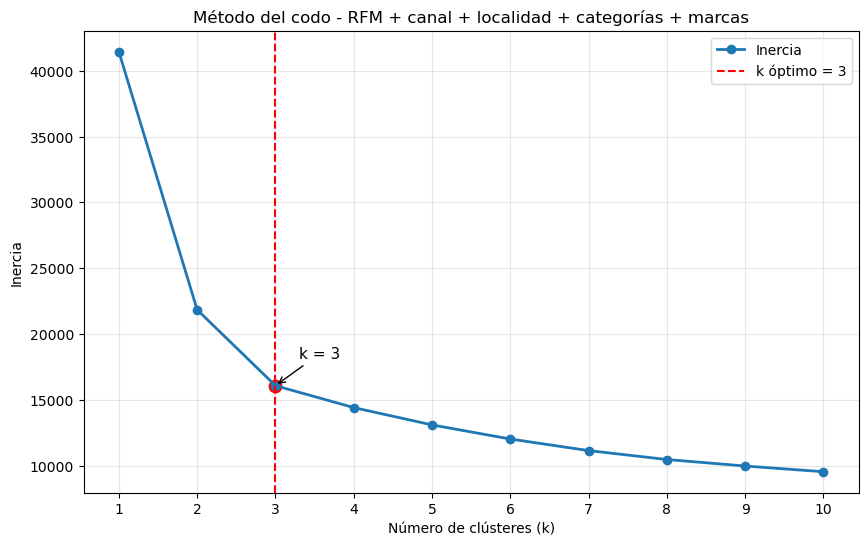

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertias, marker='o', linewidth=2, label='Inercia')

if k_optimo is not None:
    y_optimo = inertias[k_values.index(k_optimo)]
    plt.axvline(x=k_optimo, color='red', linestyle='--', label=f'k óptimo = {k_optimo}')
    plt.scatter(k_optimo, y_optimo, s=80, color='red')
    plt.annotate(
        f'k = {k_optimo}',
        xy=(k_optimo, y_optimo),
        xytext=(k_optimo + 0.3, y_optimo + 0.05 * max(inertias)),
        arrowprops=dict(arrowstyle='->'),
        fontsize=11
    )

plt.xticks(k_values)
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.title("Método del codo - RFM + canal + localidad + categorías + marcas")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [16]:
#SILHOUETTE

k=2 -> silhouette score = 0.593068
k=3 -> silhouette score = 0.339828
k=4 -> silhouette score = 0.277960
k=5 -> silhouette score = 0.172885
k=6 -> silhouette score = 0.181795
k=7 -> silhouette score = 0.184919
k=8 -> silhouette score = 0.192681
k=9 -> silhouette score = 0.187189
k=10 -> silhouette score = 0.184253


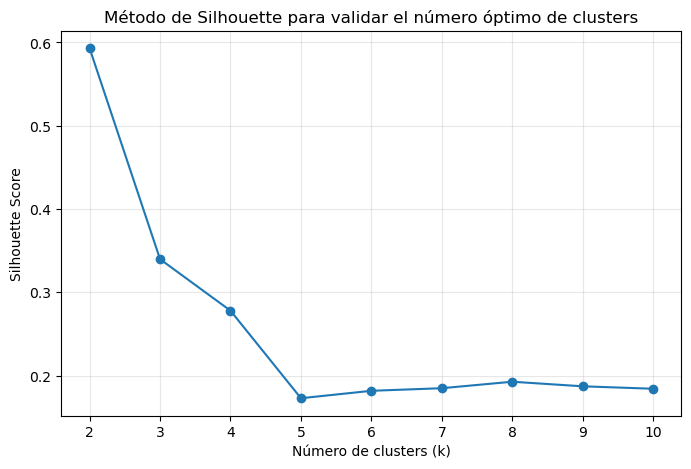


Mejor k según silhouette: 2
Mejor silhouette score: 0.593068


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Lista para guardar los resultados
silhouette_scores = []

# Rango de valores de k a evaluar
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = kmeans.fit_predict(X_final)
    score = silhouette_score(X_final, labels)
    silhouette_scores.append(score)
    print(f"k={k} -> silhouette score = {score:.6f}")

# Gráfico del método de silhouette
plt.figure(figsize=(8,5))
plt.plot(K, silhouette_scores, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Método de Silhouette para validar el número óptimo de clusters")
plt.xticks(K)
plt.grid(True, alpha=0.3)
plt.show()

# Mejor k según silhouette
best_k = K[silhouette_scores.index(max(silhouette_scores))]
best_score = max(silhouette_scores)

print(f"\nMejor k según silhouette: {best_k}")
print(f"Mejor silhouette score: {best_score:.6f}")

In [18]:
#MODELO K-MEANS

In [19]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
df["cluster"] = kmeans.fit_predict(X_final)

display(df.head())

,cliente_id,localidad_id,localidad,canal_id,canal,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,categoria_predominante,porcentaje_monto_categoria_top,marca_predominante,porcentaje_monto_marca_top,cluster
0,1,2,Ciudad del Este,2,DESPENSAS B,1,376,64621692.83,417,17,33,LAUNDRY,59.74,OMO,37.26,0
1,2,7,Juan Emilio OLeary,2,DESPENSAS B,690,65,5117624.70,88,13,18,LAUNDRY,55.74,BRILLANTE,42.64,0
2,3,10,Minga Guazú,1,DESPENSAS C,1,323,26236227.76,367,17,33,LAUNDRY,35.08,OMO,19.80,0
3,7,10,Minga Guazú,2,DESPENSAS B,4,226,16170672.80,232,15,26,LAUNDRY,64.86,OMO,39.26,0
4,9,10,Minga Guazú,14,GASTRONOMICOS,11,113,10309544.51,83,14,21,LAUNDRY,81.44,BRILLANTE,60.23,0


In [20]:
conteo_clusters = df["cluster"].value_counts().sort_index()
print(conteo_clusters)

cluster
0    3368
1     389
Name: count, dtype: int64


In [21]:
perfil_clusters = df.groupby("cluster")[[
    "recencia",
    "frecuencia_compra",
    "monto_total",
    "variedad_productos",
    "cantidad_categorias_distintas",
    "cantidad_marcas_distintas",
    "porcentaje_monto_categoria_top",
    "porcentaje_monto_marca_top"
]].mean().round(2)

display(perfil_clusters)

,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top
cluster,,,,,,,,
0,99.79,145.76,58669245.45,186.73,13.19,20.25,56.84,39.67
1,381.58,7.00,37888632.76,9.60,3.70,4.67,70.64,62.35


In [22]:
canal_por_cluster = (
    df.groupby("cluster")["canal"]
    .agg(lambda x: x.value_counts().index[0])
    .reset_index()
)
canal_por_cluster.columns = ["cluster", "canal_predominante"]

localidad_por_cluster = (
    df.groupby("cluster")["localidad"]
    .agg(lambda x: x.value_counts().index[0])
    .reset_index()
)
localidad_por_cluster.columns = ["cluster", "localidad_predominante"]

display(canal_por_cluster)
display(localidad_por_cluster)

,cluster,canal_predominante
0,0,DESPENSAS B
1,1,DESPENSAS B


,cluster,localidad_predominante
0,0,Ciudad del Este
1,1,Ciudad del Este


In [23]:
categoria_por_cluster = (
    df.groupby("cluster")["categoria_predominante"]
    .agg(lambda x: x.value_counts().index[0] if x.notna().any() else "SIN_DATO")
    .reset_index()
)
categoria_por_cluster.columns = ["cluster", "categoria_predominante_cluster"]

marca_por_cluster = (
    df.groupby("cluster")["marca_predominante"]
    .agg(lambda x: x.value_counts().index[0] if x.notna().any() else "SIN_DATO")
    .reset_index()
)
marca_por_cluster.columns = ["cluster", "marca_predominante_cluster"]

display(categoria_por_cluster)
display(marca_por_cluster)

,cluster,categoria_predominante_cluster
0,0,LAUNDRY
1,1,LAUNDRY


,cluster,marca_predominante_cluster
0,0,OMO
1,1,OMO


In [24]:
conteo_clusters_df = df["cluster"].value_counts().sort_index().reset_index()
conteo_clusters_df.columns = ["cluster", "cantidad_clientes"]

porcentaje_clusters = (
    df["cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .reset_index()
)
porcentaje_clusters.columns = ["cluster", "porcentaje_clientes"]

resumen_clusters = (
    perfil_clusters.reset_index()
    .merge(conteo_clusters_df, on="cluster")
    .merge(porcentaje_clusters, on="cluster")
    .merge(canal_por_cluster, on="cluster")
    .merge(localidad_por_cluster, on="cluster")
    .merge(categoria_por_cluster, on="cluster")
    .merge(marca_por_cluster, on="cluster")
)

display(resumen_clusters)

,cluster,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top,cantidad_clientes,porcentaje_clientes,canal_predominante,localidad_predominante,categoria_predominante_cluster,marca_predominante_cluster
0,0,99.79,145.76,58669245.45,186.73,13.19,20.25,56.84,39.67,3368,89.65,DESPENSAS B,Ciudad del Este,LAUNDRY,OMO
1,1,381.58,7.00,37888632.76,9.60,3.70,4.67,70.64,62.35,389,10.35,DESPENSAS B,Ciudad del Este,LAUNDRY,OMO


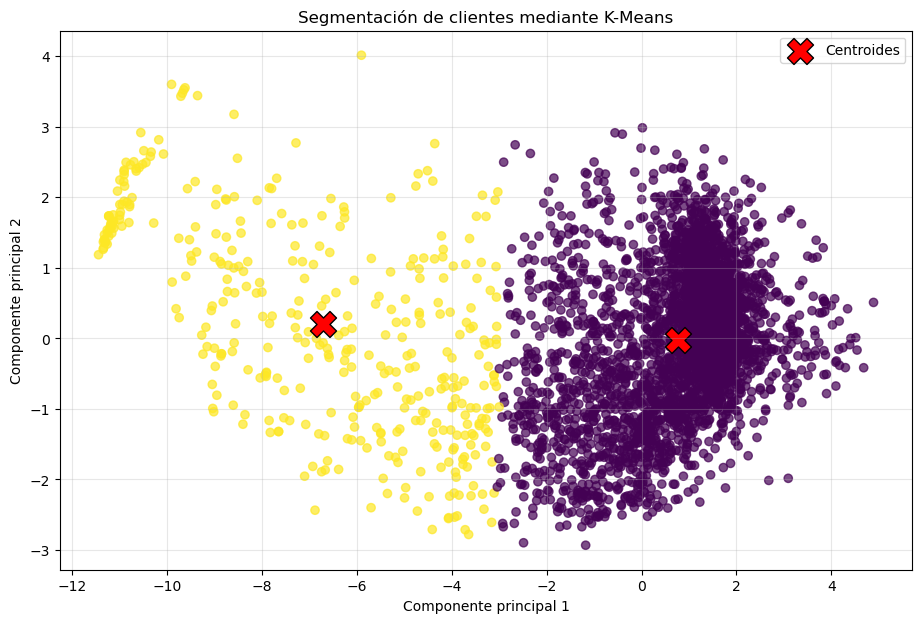

In [25]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_final)

# Datos para gráfico
df_plot = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=df.index)
df_plot["cluster"] = df["cluster"]

# Centroides con nombres de columnas correctos
centroides_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_final.columns
)
centroides_pca = pca.transform(centroides_df)

# Visualización
plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    df_plot["PC1"],
    df_plot["PC2"],
    c=df_plot["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.scatter(
    centroides_pca[:, 0],
    centroides_pca[:, 1],
    s=350,
    marker="X",
    c="red",
    edgecolors="black",
    label="Centroides"
)

plt.title("Segmentación de clientes mediante K-Means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [26]:
import pandas as pd

# Variables numéricas usadas en el clustering
variables_cluster = [
    "recencia",
    "frecuencia_compra",
    "monto_total",
    "variedad_productos",
    "cantidad_categorias_distintas",
    "cantidad_marcas_distintas",
    "porcentaje_monto_categoria_top",
    "porcentaje_monto_marca_top"
]

# Tabla resumen por cluster
tabla_clusters = df.groupby("cluster")[variables_cluster].agg([
    "mean",
    "median",
    "min",
    "max"
]).round(2)

tabla_clusters

recencia                  frecuencia_compra                   \
            mean median min   max              mean median min   max   
cluster                                                                
0          99.79    4.0   1  1057            145.76  158.0   5  1205   
1         381.58  185.0   1  1090              7.00    4.0   1   152   

         monto_total               ... cantidad_marcas_distintas      \
                mean       median  ...                       min max   
cluster                            ...                                 
0        58669245.45  12902302.56  ...                         9  47   
1        37888632.76    248388.83  ...                         1  11   

        porcentaje_monto_categoria_top                        \
                                  mean median    min     max   
cluster                                                        
0                                56.84  56.68  18.08   99.68   
1                                70.64  69.75  20.26  100.00   

        porcentaje_monto_marca_top                        
                              mean median    min     max  
cluster                                                   
0                            39.67  37.74  11.66   99.68  
1                            62.35  57.27  19.27  100.00  

[2 rows x 32 columns]

In [27]:
# Resumen simple por cluster
tabla_resumen = df.groupby("cluster")[variables_cluster].mean().round(2)

# Cantidad de clientes por cluster
tabla_resumen["cantidad_clientes"] = df["cluster"].value_counts().sort_index()

tabla_resumen

,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top,cantidad_clientes
cluster,,,,,,,,,
0,99.79,145.76,58669245.45,186.73,13.19,20.25,56.84,39.67,3368
1,381.58,7.00,37888632.76,9.60,3.70,4.67,70.64,62.35,389


In [28]:
# Cantidad de clientes por cluster
cantidad_clientes = df.groupby("cluster").size().rename("cantidad_clientes")

# Promedio de variables por cluster
promedios_clusters = df.groupby("cluster")[variables_cluster].mean().round(2)

# Unir en una sola tabla
tabla_resumen = pd.concat([cantidad_clientes, promedios_clusters], axis=1)

tabla_resumen

,cantidad_clientes,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top
cluster,,,,,,,,,
0,3368,99.79,145.76,58669245.45,186.73,13.19,20.25,56.84,39.67
1,389,381.58,7.00,37888632.76,9.60,3.70,4.67,70.64,62.35


In [29]:
tabla_resumen.style.background_gradient(cmap="Blues")

,cantidad_clientes,recencia,frecuencia_compra,monto_total,variedad_productos,cantidad_categorias_distintas,cantidad_marcas_distintas,porcentaje_monto_categoria_top,porcentaje_monto_marca_top
cluster,,,,,,,,,
0,3368,99.790000,145.760000,58669245.450000,186.730000,13.190000,20.250000,56.840000,39.670000
1,389,381.580000,7.000000,37888632.760000,9.600000,3.700000,4.670000,70.640000,62.350000


In [30]:
#MODELO APRIORI

In [31]:
ventas_query = """
SELECT
    fv.cliente_id,

    CONCAT(
        COALESCE(fv.documento_id, ''), '-',
        COALESCE(fv.serie, ''), '-',
        COALESCE(fv.numero, '')
    ) AS factura_id,

    fv.producto_code,
    cat.name AS categoria,
    mar.name AS marca,
    COALESCE(fv.neto_con_imp, 0) AS neto_con_imp,
    fv.fecha

FROM vw_fact_ventas_tipada fv

LEFT JOIN dim_productos dp
    ON fv.producto_code = dp.code

LEFT JOIN dim_categorias cat
    ON dp.categoria_id = cat.id

LEFT JOIN dim_marcas mar
    ON dp.marca_id = mar.id

WHERE fv.fecha BETWEEN '2022-01-01' AND '2024-12-31'
  AND fv.cliente_id IS NOT NULL
  AND COALESCE(fv.neto_con_imp, 0) > 0
  AND cat.name IS NOT NULL
"""

ventas = pd.read_sql(ventas_query, engine)

print("Dimensión ventas:", ventas.shape)
display(ventas.head())
print(ventas.isna().sum())

Dimensión ventas: (1895025, 7)


,cliente_id,factura_id,producto_code,categoria,marca,neto_con_imp,fecha
0,5635,8--22,-N/A-,-N/A-,-N/A-,262000.0,2024-02-07
1,5635,8--25,-N/A-,-N/A-,-N/A-,124077.0,2024-03-13
2,4419,7--33,-N/A-,-N/A-,-N/A-,532364.0,2024-08-19
3,6006,7--35,-N/A-,-N/A-,-N/A-,510407.0,2024-08-20
4,629,7--1,-N/A-,-N/A-,-N/A-,457736.0,2023-04-12


cliente_id       0
factura_id       0
producto_code    0
categoria        0
marca            0
neto_con_imp     0
fecha            0
dtype: int64


In [32]:
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Tomar clientes con su cluster asignado por K-Means
clientes_cluster = df[["cliente_id", "cluster"]].copy()

# 2. Unir el cluster con la base transaccional
# La base ventas debe tener: factura_id, cliente_id y producto/categoria/marca
ventas_cluster = ventas.merge(
    clientes_cluster,
    on="cliente_id",
    how="inner"
)

# 3. Función para crear canasta por cluster
def crear_canasta_por_cluster(data, cluster_id, trans_col="factura_id", item_col="categoria"):
    data_cluster = data[data["cluster"] == cluster_id].copy()

    canasta = (
        data_cluster
        .drop_duplicates([trans_col, item_col])
        .assign(valor=True)
        .pivot_table(
            index=trans_col,
            columns=item_col,
            values="valor",
            fill_value=False,
            aggfunc="max"
        )
        .astype(bool)
    )

    return canasta

# 4. Función para aplicar Apriori
def aplicar_apriori(canasta, min_support=0.02, min_confidence=0.50):
    itemsets = apriori(
        canasta,
        min_support=min_support,
        use_colnames=True
    )

    reglas = association_rules(
        itemsets,
        metric="confidence",
        min_threshold=min_confidence
    )

    reglas = reglas[reglas["lift"] > 1].sort_values(
        by=["lift", "confidence", "support"],
        ascending=False
    )

    return itemsets, reglas

# 5. Ejecutar Apriori para cada cluster
resultados_apriori = {}

for cluster_id in sorted(ventas_cluster["cluster"].unique()):
    canasta = crear_canasta_por_cluster(
        ventas_cluster,
        cluster_id=cluster_id,
        trans_col="factura_id",
        item_col="categoria"
    )

    itemsets, reglas = aplicar_apriori(
        canasta,
        min_support=0.02,
        min_confidence=0.50
    )

    resultados_apriori[cluster_id] = {
        "canasta": canasta,
        "itemsets": itemsets,
        "reglas": reglas
    }

    print(f"\nCluster {cluster_id}")
    print(f"Cantidad de transacciones: {canasta.shape[0]}")
    print(f"Cantidad de reglas encontradas: {len(reglas)}")

    display(reglas[[
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]].head(10))

ModuleNotFoundError: No module named 'mlxtend'

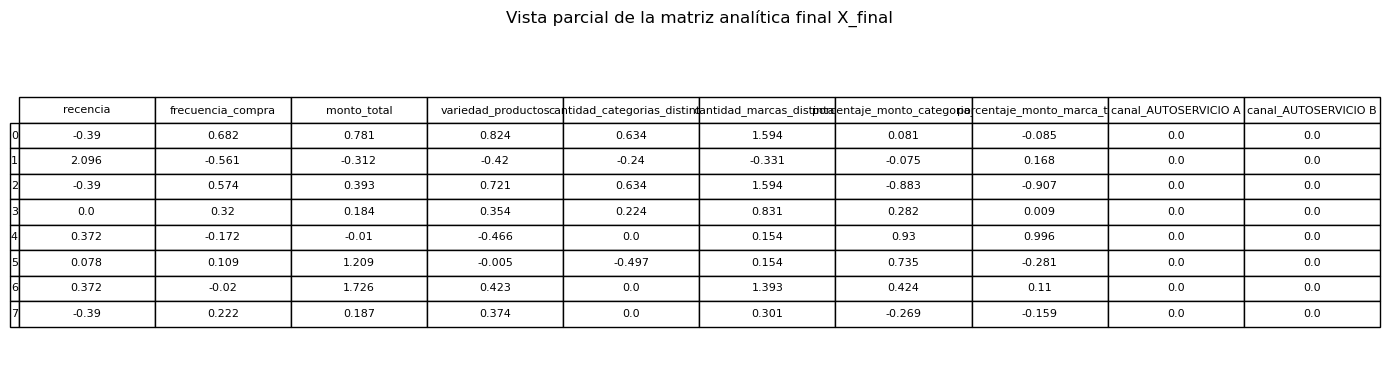

Imagen guardada en: C:\Users\evely\Downloads\xfinal_muestra.png


In [35]:
import matplotlib.pyplot as plt
from pathlib import Path

# Seleccionar una muestra pequeña de X_final
tabla_xfinal = X_final.head(8).iloc[:, :10].copy()

# Redondear valores para que se vea mejor
tabla_xfinal = tabla_xfinal.round(3)

# Crear figura
fig, ax = plt.subplots(figsize=(14, 4))
ax.axis("off")

tabla = ax.table(
    cellText=tabla_xfinal.values,
    colLabels=tabla_xfinal.columns,
    rowLabels=tabla_xfinal.index,
    cellLoc="center",
    loc="center"
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(8)
tabla.scale(1, 1.4)

plt.title("Vista parcial de la matriz analítica final X_final", fontsize=12, pad=15)
plt.tight_layout()

# Guardar en la carpeta Descargas
ruta_descargas = Path.home() / "Downloads" / "xfinal_muestra.png"

plt.savefig(ruta_descargas, dpi=300, bbox_inches="tight")
plt.show()

print(f"Imagen guardada en: {ruta_descargas}")